# 01 - Exploratory data analysis: Complete Journey grocery loyalty panel
All tables come from the DuckDB model built by `make sql` (`sql/01..09`). Raw data is not committed - run `make data` first. Source: 84.51 Complete Journey 2.0 via the `completejourney` R package, CC0.

In [1]:
import os, json, duckdb, pandas as pd, numpy as np, matplotlib.pyplot as plt
os.chdir('..') if os.path.basename(os.getcwd()) == 'notebooks' else None
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 20)
con = duckdb.connect('data/processed/grocery.duckdb', read_only=True)

## Data-quality profile and cleaning waterfall

In [2]:
con.execute('SELECT * FROM dq_report').df()

,check_name,n_rows
0,total_lines,1469307
1,distinct_households,2469
2,distinct_baskets,155848
3,exact_duplicate_lines,0
4,missing_household_or_basket,0
5,missing_timestamp,0
6,negative_quantity_lines,0
7,negative_sales_value_lines,0
8,zero_quantity_lines,8869
9,zero_quantity_positive_sales,29


In [3]:
con.execute('SELECT * FROM dq_cleaning_waterfall').df()

,step,n_rows
0,raw lines,1469307
1,"dropped: empty lines (no value, no discount)",5859
2,dropped: zero quantity with positive sales,29
3,"dropped: zero price, no discount",263
4,"kept lines (merchandise, free items, coupon-on...",1463156
5,kept: merchandise lines,1458032
6,"kept: free-item lines ($0 sales, discounted)",2143
7,kept: coupon-only lines,2981
8,kept: return lines (negative quantity or value),0
9,flagged: quantity above max (units set to NULL...,13494


## Grain and size of the clean model

In [4]:
con.execute('''SELECT 'fct_baskets' t, COUNT(*) n FROM fct_baskets UNION ALL
SELECT 'fct_days', COUNT(*) FROM fct_days UNION ALL SELECT 'dim_households', COUNT(*) FROM dim_households UNION ALL
SELECT 'campaign_exposure', COUNT(*) FROM campaign_exposure UNION ALL
SELECT 'coupon_redemptions_clean', COUNT(*) FROM coupon_redemptions_clean''').df()

,t,n
0,fct_baskets,155368
1,fct_days,127320
2,dim_households,2469
3,campaign_exposure,6589
4,coupon_redemptions_clean,2102


## Monthly spend and active households

,month,spend,households
7,2017-08-01,384425.55,2032
8,2017-09-01,367557.83,2028
9,2017-10-01,387807.05,2049
10,2017-11-01,386027.19,2061
11,2017-12-01,421719.68,2062


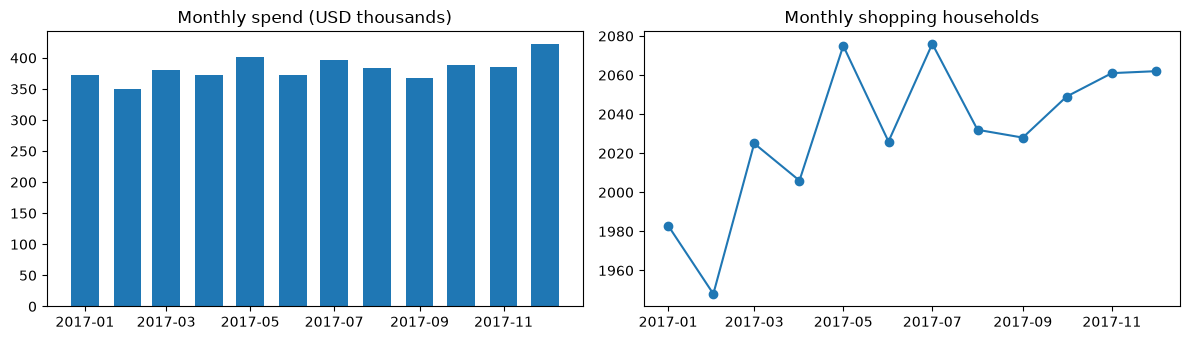

In [5]:
m = con.execute('''SELECT DATE_TRUNC('month', basket_date) AS month, SUM(spend) spend,
       COUNT(DISTINCT household_id) households FROM fct_baskets GROUP BY 1 ORDER BY 1''').df()
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].bar(m.month, m.spend / 1e3, width=20); ax[0].set_title('Monthly spend (USD thousands)')
ax[1].plot(m.month, m.households, 'o-'); ax[1].set_title('Monthly shopping households')
plt.tight_layout(); m.tail()

In [6]:
con.execute('SELECT * FROM monthly_active_households ORDER BY month_end').df().tail(6)

,month_end,active_30d,active_60d,active_90d
6,2017-07-31,2058,2236,2317
7,2017-08-31,2020,2242,2311
8,2017-09-30,2028,2227,2314
9,2017-10-31,2045,2224,2306
10,2017-11-30,2061,2242,2322
11,2017-12-31,2050,2248,2325


## Entry cohorts
The panel starts on 2017-01-01, so cohorts are entry cohorts (first observed purchase), not acquisition cohorts: the January cohort is mostly established households.

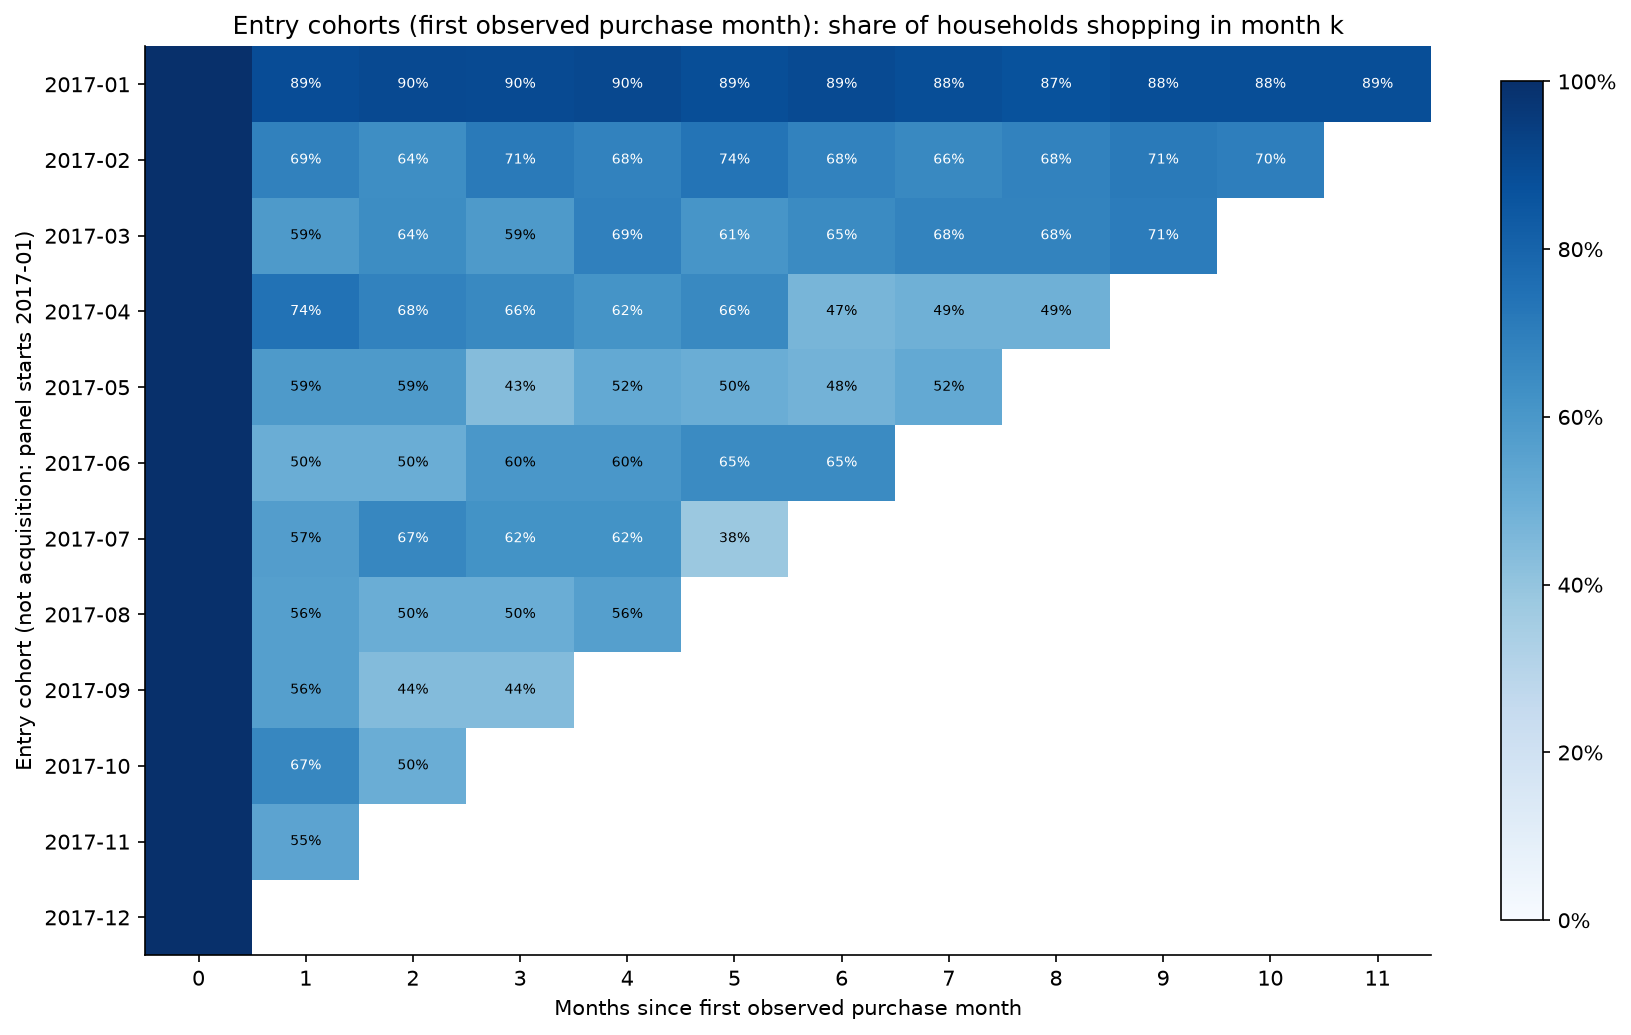

In [7]:
from IPython.display import Image; Image('docs/figures/cohort_retention_heatmap.png', width=800)

In [8]:
con.execute('''SELECT months_since_entry, AVG(retention_rate) avg_retention, COUNT(*) cohorts
FROM cohort_retention WHERE months_since_entry BETWEEN 1 AND 11 GROUP BY 1 ORDER BY 1''').df()

,months_since_entry,avg_retention,cohorts
0,1,0.627729,11
1,2,0.605332,10
2,3,0.605424,9
3,4,0.648945,8
4,5,0.631118,7
5,6,0.637303,6
6,7,0.646427,5
7,8,0.679979,4
8,9,0.767796,3
9,10,0.790404,2


## Household concentration and RFM

In [9]:
c = con.execute('SELECT lifetime_spend FROM dim_households ORDER BY 1 DESC').df()
share = c.lifetime_spend.cumsum() / c.lifetime_spend.sum()
print(f"Top 10% of households = {c.lifetime_spend.head(int(len(c)*0.1)).sum() / c.lifetime_spend.sum():.1%} of spend")
con.execute('SELECT rfm_segment, COUNT(*) n, ROUND(AVG(monetary)) avg_monetary, ROUND(AVG(recency_days)) avg_recency '
            'FROM household_rfm GROUP BY 1 ORDER BY 2 DESC').df()

Top 10% of households = 35.0% of spend


,rfm_segment,n,avg_monetary,avg_recency
0,Hibernating,667,454.0,62.0
1,Champions,642,3596.0,2.0
2,Loyal,519,2190.0,5.0
3,At risk,320,1991.0,25.0
4,Needs attention,163,645.0,7.0
5,New / Promising,158,670.0,2.0


## Department mix, discounts and coupons

In [10]:
con.execute('''SELECT dept_group, ROUND(SUM(sales_value)) spend FROM fct_lines
WHERE line_type IN ('merchandise','free_item') GROUP BY 1 ORDER BY 2 DESC''').df()

,dept_group,spend
0,grocery,2316391.0
1,fresh,1152040.0
2,health_beauty,673075.0
3,fuel,329594.0
4,other,124754.0
5,unknown,173.0


In [11]:
con.execute('''SELECT ROUND(SUM(retail_disc) / SUM(shelf_value), 4) retail_disc_share,
ROUND((SUM(coupon_disc)+SUM(coupon_match_disc)) / SUM(shelf_value), 4) coupon_share,
ROUND(AVG(CASE WHEN has_coupon THEN 1.0 ELSE 0 END), 4) baskets_with_coupon FROM fct_baskets''').df()

,retail_disc_share,coupon_share,baskets_with_coupon
0,0.1468,0.0057,0.0632


## Campaigns

In [12]:
con.execute('SELECT * FROM dim_campaigns ORDER BY start_date').df()

,campaign_id,campaign_type,start_date,end_date,duration_days,n_households_targeted,n_redeeming_households,n_redemptions,n_redeemers_in_target,redemption_rate_households
0,24,Type C,2016-11-14,2017-01-16,64,12,0,0,0,0.000000
1,25,Type B,2016-12-06,2017-02-05,62,17,1,1,1,0.058824
2,26,Type B,2016-12-28,2017-02-19,54,118,12,22,12,0.101695
3,27,Type A,2017-02-08,2017-03-26,47,361,36,64,36,0.099723
4,1,Type B,2017-03-03,2017-04-09,38,13,1,1,1,0.076923
5,2,Type B,2017-03-08,2017-04-09,33,48,2,5,2,0.041667
6,3,Type C,2017-03-13,2017-05-08,57,12,2,2,2,0.166667
7,4,Type B,2017-03-29,2017-04-30,33,81,6,11,6,0.074074
8,5,Type B,2017-04-03,2017-05-07,35,166,8,13,8,0.048193
9,6,Type C,2017-04-19,2017-05-21,33,65,1,1,1,0.015385
